# Optimisation de portefeuille par colonie de fourmis


10 actions à 10 %, univers CAC 40 ∪ CAC Mid 60, depuis le 01/01/2022.


## 1 · Comprendre le problème

Une **métaheuristique** explore un très grand ensemble de solutions sans toutes les
énumérer. Ici, une solution est un panier de **10 actions distinctes**, choisi dans
l'union du CAC 40 et du CAC Mid 60. Les poids sont fixés : **10 % par action**.
L'algorithme optimise donc la **sélection des titres**, sans solveur de pondération.

L'idée de départ est correcte : **minimiser le risque sous une contrainte de rendement
minimal**. Dans cette version, le risque est la volatilité annualisée des rendements
quotidiens. Le rendement minimal est le **CAGR**, ou taux de croissance annuel composé,
du meilleur des deux indices sur les mêmes dates. Sur une durée identique, comparer
les CAGR ou les performances cumulées donne le même classement.

Les fourmis artificielles construisent des paniers au hasard, avec une préférence
pour les actions qui portent davantage de **phéromone** et dont la volatilité
individuelle est plus faible. On évalue ensuite le panier entier : les corrélations
comptent aussi. Les meilleurs paniers renforcent les traces des actions retenues,
tandis qu'une partie des anciennes traces s'évapore. Cette boucle alterne
exploration et apprentissage. Elle trouve une bonne solution approchée, **sans
certifier le minimum global**.


On cherche $\min_{S\subset U, |S|=10}\sigma(S)$ sous $g(S)\geq \max(g_{CAC40},g_{Mid60})$. Avec $r_{S,t}=\frac{1}{10}\sum_{i\in S}r_{i,t}$, $g(S)=\exp(\sum_t\log(1+r_{S,t})/Y)-1$ et $\sigma(S)=s(r_S)\sqrt{252}$.

## 2 · Hypothèses et limites

- **Période demandée :** du 01/01/2022 à la dernière clôture de l'instantané
  local affichée dans les résultats. Les cours de l'application sont figés :
  aucune acquisition n'est déclenchée par une visite ou une relance de la colonie.
  Le 1er janvier étant fermé, les performances commencent à la première clôture
  commune disponible. Une commande locale permet au propriétaire de préparer
  un nouvel instantané ; le notebook peut aussi télécharger des cours lorsqu'il
  est exécuté localement par son utilisateur.
- **Portefeuille :** 10 actions, positions acheteuses, poids constants à 10 %.
  La moyenne quotidienne des rendements suppose un **rééquilibrage quotidien
  théorique**, sans frais, fiscalité, contraintes de liquidité ni arrondis de titres.
- **Base de comparaison :** cours `Close` Yahoo (`auto_adjust=False`), sans
  réinvestissement des dividendes, comparés aux **indices prix** CAC 40 et CAC Mid 60.
  Les prix suivent les ajustements du fournisseur ; les opérations sur titres
  complexes doivent être contrôlées. `Adj Close` inclurait notamment des ajustements
  de dividendes et appellerait des indices de rendement total comparables.
- **Sources :** actions et CAC 40 via Yahoo Finance ; CAC Mid 60 via Yahoo, ou
  complément Euronext exact si l'historique Yahoo est incomplet. Aucun ETF proxy.
- **Qualité :** même calendrier que le CAC 40 ; une action sans historique complet
  est exclue avec un motif. Aucun remplissage artificiel des prix. Si l'un des
  indices manque, le calcul est arrêté jusqu'à une correction locale de l'instantané.
- **Univers :** composition officielle figée au 23/10/2026, conservée avec ISIN,
  source et symbole Yahoo. Ce n'est pas une reconstitution des compositions de 2022.
- **Interprétation :** sélection et mesure sur la même période, benchmark gagnant
  connu a posteriori et biais de survivance. C'est une **optimisation rétrospective**,
  pas un backtest prédictif. Une étape ultérieure devra sélectionner sur une fenêtre
  passée puis mesurer hors échantillon, avec compositions historiques et frais.


## 3 · Pseudo-code commenté
```text
ENTRÉES : cours des N actions éligibles, CAC 40, CAC Mid 60, paramètres ACO
CONSTANTE : K = 10 ; chaque poids vaut 1 / K = 10 %

1. PRÉPARER LES DONNÉES
   Charger les clôtures depuis le 01/01/2022.
   # Application : instantané local, préparé manuellement hors interface publique.
   Garder les mêmes dates pour les actions et les deux indices exacts.
   Exclure et signaler toute action dont l'historique est incomplet.
   Calculer les rendements quotidiens et la durée Y en années calendaires.
   cible ← maximum(CAGR du CAC 40, CAGR du CAC Mid 60)

2. INITIALISER LA COLONIE
   rng ← générateur aléatoire fixé par seed                 # reproductibilité
   tau[i] ← 1 pour chaque action i                          # mémoire initiale
   eta[i] ← 1 / max(volatilité individuelle[i], 10^-8)       # information locale
   Normaliser eta par sa médiane ; meilleur ← aucun panier

3. POUR iteration ALLANT DE 1 À n_iterations
   Pour chaque fourmi parmi n_ants :
       panier ← ensemble vide
       Tant que le panier contient moins de K titres :
           Pour chaque action i non encore choisie :
               attraction[i] ← tau[i]^alpha × eta[i]^beta
           p[i] ← attraction[i] / somme des attractions restantes
           Tirer une action selon p, puis l'ajouter au panier # sans doublon

       r_panier[t] ← moyenne des K rendements au jour t       # poids fixes 10 %
       CAGR ← exp(somme(log(1 + r_panier)) / Y) - 1
       risque ← écart_type(r_panier, ddof=1) × racine(252)

       Si CAGR ≥ cible : classer par risque croissant        # contrainte stricte
       Sinon : classer par déficit (cible - CAGR) croissant, puis par risque
       Toujours préférer un panier admissible à un panier sous la cible.
       Mettre à jour le meilleur panier global si le classement s'améliore.

   tau ← (1 - rho) × tau                                   # évaporation
   élites ← les n_elite meilleurs paniers de cette itération
   Si le meilleur global est admissible : retirer les élites non admissibles
   dépôts ← [meilleur global] + élites
   Pour chaque panier de dépôts, de rang r allant de 0 à L - 1 :
       delta ← Q × (L - r) / (L × (L + 1) / 2)              # dépôt décroissant
       Pour chaque action i du panier : tau[i] ← tau[i] + delta
   tau ← borner(tau, tau_min, tau_max)                      # évite la stagnation
   Conserver CAGR, risque, déficit et nombre de solutions admissibles.

4. RESTITUER
   Si le meilleur respecte la cible : afficher « objectif historique atteint ».
   Sinon : afficher « aucune solution admissible trouvée », avec son déficit.
   Afficher les 10 titres, leurs poids, la convergence et les courbes base 100.
   Ne jamais présenter cette recherche approchée comme une preuve d'optimalité.

```

## 4 · Notice des paramètres

| Variable | Défaut | Signification | Effet |
|---|---|---|---|
| N | Données | Nombre d'actions ayant un historique complet ; au plus 100 dans le snapshot. | Détermine le nombre de combinaisons possibles : C(N, 10). |
| K / k | 10 (fixe) | Nombre de titres distincts dans chaque panier. | Poids w_i = 1/K, soit 10 % ; aucune vente à découvert. |
| r[i,t], r_panier[t] | Calculés | Rendement simple de l'action i et moyenne des 10 rendements au jour t. | r[i,t] = P[i,t]/P[i,t-1] - 1 ; rééquilibrage quotidien implicite. |
| Y, 252 | Calculés / 252 | Y = jours calendaires / 365,25 ; 252 séances conventionnelles par an. | Y annualise le CAGR ; 252 annualise la volatilité. |
| cible | max(CAGR des indices) | Rendement composé minimal à respecter sur la période observée. | Contrainte calculée sur les mêmes clôtures et la même durée. |
| n_ants | 40 | Nombre de paniers construits à chaque itération. | Davantage de fourmis élargit l'exploration mais augmente le temps de calcul. |
| n_iterations | 80 | Nombre de cycles construction, évaluation, évaporation, dépôt. | Budget de 3 200 paniers tirés par défaut ; des doublons sont possibles. |
| tau[i] / τᵢ | 1 initialement | Quantité de phéromone attachée à l'action i. | Mémoire des paniers bien classés ; ce n'est ni un rendement ni un poids financier. |
| eta[i] / ηᵢ | 1 / volatilité | Attractivité locale, normalisée par sa médiane. | Favorise les titres moins volatils ; les covariances interviennent dans le risque du panier. |
| alpha / α | 1,0 | Influence de la phéromone dans la probabilité de tirage. | α = 0 ignore la mémoire ; α élevé renforce l'exploitation. |
| beta / β | 2,0 | Influence de l'heuristique eta dans le tirage. | β = 0 ignore eta ; β élevé privilégie les faibles volatilités individuelles. |
| rho / ρ | 0,20 | Fraction de phéromone qui disparaît à chaque cycle, dans ]0,1]. | ρ = 0,20 : 20 % s'évapore et 80 % reste, avant les nouveaux dépôts. |
| n_elite | 5 | Nombre maximal de paniers de l'itération autorisés à renforcer les traces. | Le meilleur global dépose aussi ; les non-admissibles cessent de déposer dès qu'un admissible existe. |
| Q / q | 1,0 | Quantité totale déposée par cycle, répartie selon les rangs. | Q règle le renforcement, en interaction avec rho et les bornes de tau. |
| L, r, delta / Δτ | Calculés | Nombre de dépôts, rang de dépôt (à partir de 0) et quantité déposée. | Δτ = Q(L-r) / [L(L+1)/2] sur chaque action du panier. |
| tau_min, tau_max | 0,05 / 5,0 | Bornes positives appliquées aux traces après les dépôts. | Empêchent une action de devenir totalement impossible ou excessivement dominante. |
| p[i] | Calculée | Probabilité conditionnelle de choisir une action restante. | Proportionnelle à τᵢ^α ηᵢ^β ; recalculée après chaque choix sans remise. |
| seed | 42 | Graine du générateur aléatoire. | Même graine + données + paramètres + environnement : même recherche. |
| 10^-8, 10^-12 | Constantes numériques | Plancher de volatilité de eta et tolérance de comparaison du CAGR. | Évite la division par zéro ; tolérance de 10^-12 en rendement décimal. |
| ddof=1 | Convention statistique | Écart-type empirique calculé avec un dénominateur T-1. | Volatilité annuelle = écart-type quotidien × √252. |

## 5 · Environnement Python

Python 3.10 ou supérieur. Décommenter la cellule suivante uniquement si les bibliothèques ne sont pas déjà installées.

In [1]:
# %pip install numpy pandas yfinance requests beautifulsoup4 cryptography matplotlib

In [2]:
"""Sélection de titres par colonie de fourmis, sans solveur de pondération.

Le même fichier alimente Streamlit et le notebook autonome généré par build_notebook.py.
"""
from __future__ import annotations

from dataclasses import dataclass, asdict
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path
from io import StringIO
import base64
import hashlib
import json
import math

import numpy as np
import pandas as pd
import requests
import yfinance as yf
from bs4 import BeautifulSoup
from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes

START = "2022-01-01"
BENCHMARKS = {"^FCHI": "CAC 40", "^CM100": "CAC Mid 60"}
MID60_PAGE = "https://live.euronext.com/en/product/indices/QS0010989117-XPAR"
MID60_CHART = "https://live.euronext.com/intraday_chart/getChartData/QS0010989117-XPAR/max"


def paris_today() -> str:
    """Borne exclusive : seules les séances antérieures au jour courant sont utilisées."""
    return datetime.now(ZoneInfo("Europe/Paris")).date().isoformat()

## 6 · Univers d'investissement

Snapshot officiel Euronext du **23/10/2026** : 40 + 60 titres. Les ISIN permettent de contrôler les correspondances Yahoo. Les titres trop récents ou incomplets seront exclus explicitement. Utiliser cette composition actuelle depuis 2022 introduit un biais de survivance.

In [3]:
# Snapshot intégré pour que ce fichier reste partageable seul.
UNIVERSE_CSV = """
ticker,name,isin,index,exchange,snapshot_date,source
AC.PA,ACCOR,FR0000120404,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
AI.PA,AIR LIQUIDE,FR0000120073,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
AIR.PA,AIRBUS,NL0000235190,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
MT.AS,ARCELORMITTAL SA,LU1598757687,CAC 40,Euronext Amsterdam,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
CS.PA,AXA,FR0000120628,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
BNP.PA,BNP PARIBAS ACT.A,FR0000131104,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
EN.PA,BOUYGUES,FR0000120503,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
BVI.PA,BUREAU VERITAS,FR0006174348,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
CAP.PA,CAPGEMINI,FR0000125338,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
CA.PA,CARREFOUR,FR0000120172,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ACA.PA,CREDIT AGRICOLE,FR0000045072,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
BN.PA,DANONE,FR0000120644,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
DSY.PA,DASSAULT SYSTEMES,FR0014003TT8,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
FGR.PA,EIFFAGE,FR0000130452,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ENGI.PA,ENGIE,FR0010208488,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
EL.PA,ESSILORLUXOTTICA,FR0000121667,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ERF.PA,EUROFINS SCIENT.,FR0014000MR3,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ENX.PA,EURONEXT,NL0006294274,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
RMS.PA,HERMES INTL,FR0000052292,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
KER.PA,KERING,FR0000121485,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
OR.PA,L'OREAL,FR0000120321,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
LR.PA,LEGRAND,FR0010307819,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
MC.PA,LVMH,FR0000121014,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ML.PA,MICHELIN,FR001400AJ45,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ORA.PA,ORANGE,FR0000133308,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
RI.PA,PERNOD RICARD,FR0000120693,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
PUB.PA,PUBLICIS GROUPE SA,FR0000130577,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
RNO.PA,RENAULT,FR0000131906,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
SAF.PA,SAFRAN,FR0000073272,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
SGO.PA,SAINT GOBAIN,FR0000125007,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
SAN.PA,SANOFI,FR0000120578,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
SU.PA,SCHNEIDER ELECTRIC,FR0000121972,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
GLE.PA,SOCIETE GENERALE,FR0000130809,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
STLAP.PA,STELLANTIS NV,NL00150001Q9,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
STMPA.PA,STMICROELECTRONICS,NL0000226223,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
HO.PA,THALES,FR0000121329,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
TTE.PA,TOTALENERGIES,FR0000120271,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
URW.PA,UNIBAIL-RODAMCO-WE,FR0013326246,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
VIE.PA,VEOLIA ENVIRON.,FR0000124141,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
DG.PA,VINCI,FR0000125486,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/FR0003500008-XPAR
ADP.PA,ADP,FR0010340141,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
AF.PA,AIR FRANCE -KLM,FR001400J770,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ATE.PA,ALTEN,FR0000071946,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
APAM.AS,APERAM,LU0569974404,CAC Mid 60,Euronext Amsterdam,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ARG.PA,ARGAN,FR0010481960,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ATO.PA,ATOS GROUP,FR001400X2S4,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
AYV.PA,AYVENS,FR0013258662,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
BB.PA,BIC,FR0000120966,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
BOL.PA,BOLLORE,FR0000039299,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
CARM.PA,CARMILA,FR0010828137,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
CLARI.PA,CLARIANE,FR0010386334,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
COFA.PA,COFACE,FR0010667147,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
COV.PA,COVIVIO,FR0000064578,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
DBV.PA,DBV TECHNOLOGIES,FR0010417345,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
DBG.PA,DERICHEBOURG,FR0000053381,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ELIS.PA,ELIS,FR0012435121,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
EMEIS.PA,EMEIS,FR001400NLM4,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ERA.PA,ERAMET,FR0000131757,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
RF.PA,EURAZEO,FR0000121121,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ETL.PA,EUTELSAT COMMUNIC.,FR0010221234,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
EXA.PA,EXAIL TECHNOLOGIES,FR0000062671,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
EXENS.PA,EXOSENS,FR001400Q9V2,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
FDJU.PA,FDJ UNITED,FR0013451333,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
FRVIA.PA,FORVIA,FR0000121147,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
GFC.PA,GECINA,FR0010040865,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
GNFT.PA,GENFIT,FR0004163111,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
ICAD.PA,ICADE,FR0000035081,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
IDL.PA,ID LOGISTICS GROUP,FR0010929125,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
NK.PA,IMERYS,FR0000120859,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
IVA.PA,INVENTIVA,FR0013233012,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
IPS.PA,IPSOS,FR0000073298,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
DEC.PA,JCDECAUX,FR0000077919,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
FII.PA,LISI,FR0000050353,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
MAU.PA,MAUREL ET PROM,FR0000051070,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
MEDCL.PA,MEDINCELL,FR0004065605,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
MERY.PA,MERCIALYS,FR0010241638,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
MRN.PA,MERSEN,FR0000039620,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
MMT.PA,METROPOLE TV,FR0000053225,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
NANO.PA,NANOBIOTIX,FR0011341205,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
OPM.PA,OPMOBILITY,FR0000124570,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
PLX.PA,PLUXEE,NL0015001W49,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
RCO.PA,REMY COINTREAU,FR0000130395,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
RUI.PA,RUBIS,FR0013269123,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
SK.PA,S.E.B.,FR0000121709,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
SESG.PA,SES,LU0088087324,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
SOLB.BR,SOLVAY,BE0003470755,CAC Mid 60,Euronext Brussels,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
SOP.PA,SOPRA STERIA GROUP,FR0000050809,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
TFI.PA,TF1,FR0000054900,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
TRI.PA,TRIGANO,FR0005691656,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
UBI.PA,UBISOFT ENTERTAIN,FR0000054470,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
FR.PA,VALEO,FR0013176526,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VK.PA,VALLOUREC,FR0013506730,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VLA.PA,VALNEVA,FR0004056851,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VCT.PA,VICAT,FR0000031775,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VIRP.PA,VIRBAC,FR0000031577,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VIRI.PA,VIRIDIEN,FR001400PVN6,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VIV.PA,VIVENDI SE,FR0000127771,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
VU.PA,Vusion,FR0010282822,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
MF.PA,WENDEL,FR0000121204,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
WLN.PA,WORLDLINE,FR00140182K6,CAC Mid 60,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/QS0010989117-XPAR
"""
universe = pd.read_csv(StringIO(UNIVERSE_CSV))
assert len(universe) == 100 and universe["ticker"].is_unique
display(universe.groupby("index").size().rename("Nombre de titres"))
display(universe.head())

index
CAC 40        40
CAC Mid 60    60
Name: Nombre de titres, dtype: int64

,ticker,name,isin,index,exchange,snapshot_date,source
0,AC.PA,ACCOR,FR0000120404,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/F...
1,AI.PA,AIR LIQUIDE,FR0000120073,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/F...
2,AIR.PA,AIRBUS,NL0000235190,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/F...
3,MT.AS,ARCELORMITTAL SA,LU1598757687,CAC 40,Euronext Amsterdam,2026-10-23,https://live.euronext.com/en/product/indices/F...
4,CS.PA,AXA,FR0000120628,CAC 40,Euronext Paris,2026-10-23,https://live.euronext.com/en/product/indices/F...


### Données et contrôle qualité

Yahoo fournit les clôtures des actions et du CAC 40. Si ^CM100 est incomplet, on lit l'historique du graphique **public** Euronext de l'indice exact. La clé de format est fournie sur la page publique, sans authentification. Toute erreur de couverture bloque le calcul ; aucun prix manquant n'est rempli. Le parseur de CSV permet aussi un import manuel.

In [5]:
def decode_public_euronext(payload: dict, public_format_key: str):
    """Lire le format du graphique public, comme le JavaScript fourni sur la page.

    Aucune connexion ni donnée privée : la clé de format est publiée dans
    drupalSettings.ajax_secure.kye. Le format peut changer côté Euronext.
    """
    salt = bytes.fromhex(payload["s"])
    derived, previous = b"", b""
    while len(derived) < 48:
        previous = hashlib.md5(previous + public_format_key.encode() + salt).digest()
        derived += previous
    decoder = Cipher(algorithms.AES(derived[:32]), modes.CBC(bytes.fromhex(payload["iv"]))).decryptor()
    plain = decoder.update(base64.b64decode(payload["ct"])) + decoder.finalize()
    return json.loads(plain[:-plain[-1]])


def fetch_official_mid60(start: str, end: str) -> pd.Series:
    """Historique de l'indice prix CAC Mid 60 exact (aucun ETF de substitution)."""
    with requests.Session() as session:
        page = session.get(MID60_PAGE, timeout=40)
        page.raise_for_status()
        soup = BeautifulSoup(page.text, "html.parser")
        node = soup.select_one('script[data-drupal-selector="drupal-settings-json"]')
        if node is None:
            raise ValueError("Format Euronext modifié : importer un CSV Date,Close de l'indice exact.")
        settings = json.loads(node.string)
        response = session.get(MID60_CHART, timeout=40)
        response.raise_for_status()
        payload = response.json()
        rows = decode_public_euronext(payload, settings["ajax_secure"]["kye"]) if isinstance(payload, dict) and "ct" in payload else payload
    frame = pd.DataFrame(rows)
    dates = pd.to_datetime(frame["time"]).dt.normalize()
    series = pd.Series(pd.to_numeric(frame["price"]).to_numpy(), index=dates, name="^CM100")
    series = series[~series.index.duplicated(keep="last")].sort_index()
    return series.loc[(series.index >= pd.Timestamp(start)) & (series.index < pd.Timestamp(end))]


def read_mid60_csv(content: str) -> pd.Series:
    """CSV simple Date,Close, ou export Euronext avec son préambule."""
    lines = content.lstrip("\ufeff").splitlines()
    header = next((i for i, line in enumerate(lines) if line.lower().startswith("date,") or line.lower().startswith("date;")), None)
    if header is None:
        raise ValueError("Le CSV doit contenir les colonnes Date et Close.")
    separator = ";" if ";" in lines[header] else ","
    columns = lines[header].replace('"', '').split(separator)
    # Certains exports Euronext ont un séparateur final absent de l'en-tête.
    rows = [line.split(separator)[:len(columns)] for line in lines[header+1:] if line.strip()]
    frame = pd.DataFrame(rows, columns=columns)
    frame.columns = frame.columns.str.strip().str.lower()
    if "close" not in frame:
        raise ValueError("Colonne Close manquante.")
    dates = pd.to_datetime(frame["date"], format="mixed", dayfirst=separator == ";", errors="raise")
    values = pd.to_numeric(frame["close"].str.replace('"', '').str.replace(" ", "").str.replace(",", "."), errors="raise")
    if dates.duplicated().any() or not np.isfinite(values).all() or (values <= 0).any():
        raise ValueError("Dates uniques et cours strictement positifs requis.")
    return pd.Series(values.to_numpy(), index=dates, name="^CM100").sort_index()


def fetch_market_data(universe: pd.DataFrame, end: str | None = None) -> tuple[pd.DataFrame, dict]:
    """Télécharger Yahoo, puis compléter l'indice Mid 60 exact si nécessaire."""
    end = end or paris_today()
    tickers = universe["ticker"].tolist() + list(BENCHMARKS)
    chunks = []
    for offset in range(0, len(tickers), 20):
        raw = yf.download(tickers[offset:offset+20], start=START, end=end,
                          auto_adjust=False, actions=False, progress=False, threads=4, timeout=25)
        if raw is not None and not raw.empty:
            close = raw["Close"]
            if isinstance(close, pd.Series):
                close = close.to_frame(tickers[offset])
            chunks.append(close)
    if not chunks:
        raise ValueError("Yahoo n'a renvoyé aucun historique. Réessayer plus tard.")
    prices = pd.concat(chunks, axis=1).reindex(columns=tickers)
    prices.index = pd.to_datetime(prices.index).tz_localize(None).normalize()
    prices = prices[~prices.index.duplicated(keep="last")].sort_index()
    prices = prices.loc[(prices.index >= START) & (prices.index < end)]
    if prices["^FCHI"].notna().sum() < 252:
        raise ValueError("Historique CAC 40 Yahoo insuffisant.")
    calendar = prices["^FCHI"].dropna().index
    notes = []
    source = "Yahoo Finance (^CM100)"
    if prices["^CM100"].reindex(calendar).isna().any():
        try:
            official = fetch_official_mid60(START, end)
            # Source unique : ne pas raccorder une cotation Yahoo intraday à une clôture officielle.
            prices["^CM100"] = official.reindex(prices.index)
            source = "Euronext · graphique public de l'indice prix CAC Mid 60"
            notes.append("Yahoo ^CM100 incomplet : historique exact complété par Euronext, sans proxy.")
        except (requests.RequestException, ValueError, KeyError, TypeError) as exc:
            notes.append(f"Complément Euronext indisponible ({type(exc).__name__}) : importer Date,Close.")
    metadata = {"requested_start": START, "end_exclusive": end,
                "fetched_at": datetime.now(ZoneInfo("Europe/Paris")).isoformat(),
                "price_basis": "Close Yahoo sans dividendes réinvestis ; indices prix",
                "mid60_source": source, "notes": notes}
    return prices, metadata


def prepare_data(prices: pd.DataFrame, universe: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Même calendrier et même période ; aucun remplissage des cours manquants."""
    if not isinstance(prices.index, pd.DatetimeIndex) or prices.index.has_duplicates or not prices.columns.is_unique:
        raise ValueError("Dates et colonnes doivent être uniques.")
    prices = prices.sort_index()
    if any(symbol not in prices for symbol in BENCHMARKS):
        raise ValueError("Les deux indices exacts sont obligatoires.")
    reference = prices["^FCHI"].dropna()
    if len(reference) < 252 or reference.index[0] > pd.Timestamp(START) + pd.Timedelta(days=7):
        raise ValueError("Le CAC 40 doit couvrir la période demandée depuis janvier 2022.")
    calendar = reference.index
    benchmarks = prices.reindex(calendar)[list(BENCHMARKS)]
    if benchmarks.isna().any().any() or not np.isfinite(benchmarks).all().all() or (benchmarks <= 0).any().any():
        raise ValueError("Historique CAC Mid 60 incomplet sur la période depuis 2022 : actualiser ou importer le CSV exact. Aucune comparaison partielle n'est présentée comme complète.")
    eligible, audit = [], []
    for row in universe.to_dict("records"):
        series = prices.reindex(calendar).get(row["ticker"], pd.Series(index=calendar, dtype=float))
        missing = int(series.isna().sum())
        valid = missing == 0 and np.isfinite(series).all() and (series > 0).all()
        observed = series.dropna()
        audit.append({**row, "eligible": bool(valid), "missing_sessions": missing,
                      "first_quote": str(observed.index.min().date()) if len(observed) else "—",
                      "reason": "Historique complet" if valid else "Cours absent, non positif ou historique incomplet",
                      "large_moves": int((series.pct_change(fill_method=None).abs() > .5).sum())})
        if valid:
            eligible.append(row["ticker"])
    if len(eligible) < 10:
        raise ValueError(f"Seulement {len(eligible)} actions ont un historique complet ; au moins 10 sont nécessaires.")
    return prices.loc[calendar, eligible], benchmarks, pd.DataFrame(audit)

### Mesures financières

Le CAGR utilise les années calendaires. La volatilité utilise 252 séances par an. La baisse maximale inclut le capital initial pour ne pas ignorer la première perte.

In [6]:
def return_metrics(returns: pd.Series, years: float) -> dict:
    """CAGR calendaire, volatilité annualisée et baisse maximale (capital initial inclus)."""
    values = np.asarray(returns, dtype=float)
    if len(values) < 2 or years <= 0 or not np.isfinite(values).all() or (values <= -1).any():
        raise ValueError("Rendements finis > -100 %, durée positive et au moins deux observations requis.")
    wealth = np.r_[1., np.cumprod(1. + values)]
    return {"cagr": float(np.expm1(np.log1p(values).sum() / years)),
            "volatility": float(values.std(ddof=1) * np.sqrt(252)),
            "total_return": float(wealth[-1] - 1),
            "max_drawdown": float((wealth / np.maximum.accumulate(wealth) - 1).min())}


def calendar_years(index: pd.DatetimeIndex) -> float:
    return (index[-1] - index[0]).days / 365.25


def benchmark_target(benchmarks: pd.DataFrame) -> tuple[float, str, pd.DataFrame]:
    years = calendar_years(benchmarks.index)
    stats = pd.DataFrame({BENCHMARKS.get(symbol, symbol): return_metrics(series.pct_change(fill_method=None).dropna(), years)
                          for symbol, series in benchmarks.items()}).T
    winner = stats["cagr"].idxmax()
    return float(stats.loc[winner, "cagr"]), winner, stats

### Paramètres et classement des solutions

Le classement est strict : un panier admissible passe toujours devant un panier sous le seuil. Entre admissibles, on minimise la volatilité. En absence d'admissible, on minimise d'abord le déficit de CAGR.

In [8]:
@dataclass(frozen=True)
class ACOConfig:
    k: int = 10
    n_ants: int = 40
    n_iterations: int = 80
    alpha: float = 1.0
    beta: float = 2.0
    rho: float = .20
    n_elite: int = 5
    q: float = 1.0
    tau_min: float = .05
    tau_max: float = 5.0
    seed: int = 42

    def validate(self, n_assets: int):
        if not 1 <= self.k <= n_assets or self.n_ants < 1 or self.n_iterations < 1:
            raise ValueError("Cardinalité et budget de recherche invalides.")
        if not 1 <= self.n_elite <= self.n_ants:
            raise ValueError("n_elite doit être compris entre 1 et n_ants.")
        if not 0 < self.rho <= 1 or self.alpha < 0 or self.beta < 0 or self.q <= 0:
            raise ValueError("rho ∈ ]0,1], alpha/beta ≥ 0 et Q > 0 requis.")
        if not 0 < self.tau_min <= 1 <= self.tau_max:
            raise ValueError("0 < tau_min ≤ tau_initial = 1 ≤ tau_max requis.")
        if not np.isfinite([self.alpha, self.beta, self.rho, self.q, self.tau_min, self.tau_max]).all():
            raise ValueError("Paramètres finis requis.")


def solution_rank(cagr: float, volatility: float, target: float) -> tuple:
    """Une solution admissible passe toujours avant une solution sous le seuil."""
    if cagr + 1e-12 >= target:
        return (0, volatility, -cagr)
    return (1, target - cagr, volatility)

### Algorithme des fourmis

Une phéromone par action. Le tirage pondéré sans remise correspond au pseudo-code séquentiel. Les paniers déjà vus sont mémorisés pour éviter de recalculer leurs métriques. Les dépôts sont classés par rang, puis bornés. Aucun solveur et aucune optimisation des poids.

In [7]:
def optimize_aco(returns: pd.DataFrame, target: float, years: float,
                 config: ACOConfig = ACOConfig(), progress=None) -> dict:
    """Chercher un sous-ensemble : les poids restent exactement égaux à 1/k.

    Chaque fourmi tire k titres sans remise. L'heuristique privilégie les titres
    moins volatils ; l'évaluation finale tient compte de leurs covariances.
    Le CAGR composé sert à la contrainte et la volatilité sert à l'objectif.
    """
    config.validate(returns.shape[1])
    matrix = returns.to_numpy(dtype=float)
    if len(matrix) < 2 or not np.isfinite(matrix).all() or (matrix <= -1).any() or not math.isfinite(target) or years <= 0:
        raise ValueError("Rendements, objectif ou durée invalides.")
    rng = np.random.default_rng(config.seed)
    n = matrix.shape[1]
    tau = np.ones(n)  # Une trace par action ; l'ordre des titres n'a pas d'importance.
    asset_vol = matrix.std(axis=0, ddof=1) * np.sqrt(252)
    eta = 1. / np.maximum(asset_vol, 1e-8)
    eta /= np.median(eta)  # Normalisation sans effet sur les probabilités.
    best, best_rank = None, None
    cache, history = {}, []
    for iteration in range(1, config.n_iterations + 1):
        log_attractiveness = config.alpha * np.log(tau) + config.beta * np.log(eta)
        attractiveness = np.exp(log_attractiveness - log_attractiveness.max())
        attractiveness = np.maximum(attractiveness, np.finfo(float).tiny)
        probabilities = attractiveness / attractiveness.sum()
        colony = []
        for _ in range(config.n_ants):
            selection = tuple(sorted(rng.choice(n, size=config.k, replace=False, p=probabilities).tolist()))
            if selection not in cache:
                daily = matrix[:, selection].mean(axis=1)  # 10 % par titre chaque jour.
                cache[selection] = return_metrics(pd.Series(daily), years)
            metrics = cache[selection]
            rank = solution_rank(metrics["cagr"], metrics["volatility"], target)
            colony.append((rank, selection, metrics))
            if best_rank is None or rank < best_rank:
                best_rank = rank
                best = (selection, metrics.copy())
        colony.sort(key=lambda candidate: candidate[0])
        # Évaporation : rho = 0.20 signifie que 20 % de la trace disparaît.
        tau *= 1. - config.rho
        elites = colony[:config.n_elite]
        # Si une solution admissible existe, aucune solution non admissible ne dépose.
        if best_rank[0] == 0:
            elites = [entry for entry in elites if entry[0][0] == 0]
        # Le meilleur global renforce aussi la mémoire de la recherche.
        deposits = [(best_rank, best[0], best[1])] + elites
        normalizer = len(deposits) * (len(deposits) + 1) / 2
        for rank_number, (_, selection, _) in enumerate(deposits):
            tau[list(selection)] += config.q * (len(deposits) - rank_number) / normalizer
        tau = np.clip(tau, config.tau_min, config.tau_max)
        history.append({"iteration": iteration, **best[1], "feasible": best_rank[0] == 0,
                        "shortfall": max(0., target - best[1]["cagr"]),
                        "feasible_ants": sum(entry[0][0] == 0 for entry in colony),
                        "unique_evaluated": len(cache)})
        if progress:
            progress(iteration / config.n_iterations)
    selection, metrics = best
    return {"tickers": returns.columns[list(selection)].tolist(), "metrics": metrics,
            "feasible": bool(best_rank[0] == 0), "target": target,
            "history": pd.DataFrame(history),
            "pheromones": pd.Series(tau, index=returns.columns).sort_values(ascending=False),
            "config": asdict(config), "unique_evaluated": len(cache)}


def wealth_curves(prices: pd.DataFrame, benchmarks: pd.DataFrame, tickers: list[str]) -> pd.DataFrame:
    daily = prices[tickers].pct_change(fill_method=None).iloc[1:].mean(axis=1)
    portfolio = pd.concat([pd.Series([100.], index=prices.index[:1]), 100. * (1. + daily).cumprod()])
    curves = 100. * benchmarks / benchmarks.iloc[0]
    curves = curves.rename(columns=BENCHMARKS)
    curves.insert(0, "Portefeuille ACO · rétrospectif", portfolio)
    return curves

## 7 · Paramétrer l'expérience

Les paramètres modifiables sont regroupés ici. Pour comparer plusieurs réglages, conserver les mêmes données et varier la graine ou un paramètre à la fois.

In [8]:
config = ACOConfig(
    k=10,                # 10 actions, donc 10 % chacune
    n_ants=40,           # paniers proposés par cycle
    n_iterations=80,     # nombre de cycles
    alpha=1.0,           # influence de la mémoire
    beta=2.0,            # influence de l'inverse de la volatilité
    rho=0.20,            # 20 % des phéromones disparaissent par cycle
    n_elite=5,           # meilleurs paniers du cycle autorisés à déposer
    q=1.0,               # intensité totale des dépôts par cycle
    tau_min=0.05,        # maintient une probabilité d'exploration
    tau_max=5.0,         # limite la domination des traces
    seed=42,             # reproductibilité
)
# Facultatif : chemin d'un CSV Date,Close de l'indice prix CAC Mid 60 exact.
MID60_CSV = None
print(asdict(config))

{'k': 10, 'n_ants': 40, 'n_iterations': 80, 'alpha': 1.0, 'beta': 2.0, 'rho': 0.2, 'n_elite': 5, 'q': 1.0, 'tau_min': 0.05, 'tau_max': 5.0, 'seed': 42}


## 8 · Télécharger et auditer les données

La borne de fin est dynamique, en heure de Paris, et exclusive : la séance en cours n'est pas incluse. Le 01/01/2022 étant fermé, la base est la première clôture commune disponible. Le périmètre et les exclusions sont affichés.

In [9]:
prices_all, metadata = fetch_market_data(universe)
if MID60_CSV is not None:
    imported = read_mid60_csv(Path(MID60_CSV).read_text(encoding='utf-8-sig'))
    prices_all['^CM100'] = imported.reindex(prices_all.index)
    metadata['mid60_source'] = str(MID60_CSV)
prices, benchmarks, audit = prepare_data(prices_all, universe)
print(json.dumps(metadata, ensure_ascii=False, indent=2))
print(f'Période : {prices.index[0].date()} → {prices.index[-1].date()}')
print(f'{len(prices)} clôtures ; {prices.shape[1]} / 100 actions éligibles ; aucun remplissage des cours')
display(audit.loc[~audit.eligible, ['ticker','name','first_quote','missing_sessions','reason']])
display(audit.loc[audit.large_moves > 0, ['ticker','large_moves']].rename(columns={'large_moves':'Séances avec variation > 50 % à contrôler'}))
target, winner, benchmark_stats = benchmark_target(benchmarks)
print(f'Benchmark gagnant : {winner} ; CAGR minimal = {target:.2%}')
display(benchmark_stats.style.format('{:.2%}'))

$^CM100: possibly delisted; no price data found  (1d 2022-01-01 -> 2026-10-23)



1 Failed download:


['^CM100']: possibly delisted; no price data found  (1d 2022-01-01 -> 2026-10-23)


{
  "requested_start": "2022-01-01",
  "end_exclusive": "2026-10-23",
  "fetched_at": "2026-10-23T16:22:13.290744+02:00",
  "price_basis": "Close Yahoo sans dividendes réinvestis ; indices prix",
  "mid60_source": "Euronext · graphique public de l'indice prix CAC Mid 60",
  "notes": [
    "Yahoo ^CM100 incomplet : historique exact complété par Euronext, sans proxy."
  ]
}
Période : 2022-01-03 → 2026-10-22
1230 clôtures ; 97 / 100 actions éligibles ; aucun remplissage des cours


,ticker,name,first_quote,missing_sessions,reason
37,URW.PA,UNIBAIL-RODAMCO-WE,2023-04-14,329,"Cours absent, non positif ou historique incomplet"
61,EXENS.PA,EXOSENS,2024-06-07,622,"Cours absent, non positif ou historique incomplet"
80,PLX.PA,PLUXEE,2024-02-01,534,"Cours absent, non positif ou historique incomplet"


,ticker,Séances avec variation > 50 % à contrôler
45,ATO.PA,7
53,DBV.PA,1
56,EMEIS.PA,2
59,ETL.PA,3
69,IVA.PA,1
78,NANO.PA,1
96,VIV.PA,1
97,VU.PA,1
99,WLN.PA,1


Benchmark gagnant : CAC 40 ; CAGR minimal = 1.66%


,cagr,volatility,total_return,max_drawdown
CAC 40,1.66%,16.26%,8.23%,-23.04%
CAC Mid 60,-3.43%,17.52%,-15.43%,-26.80%


## 9 · Exécuter la colonie

Toutes les métriques sont estimées sur la période qui sert à sélectionner les titres. Les résultats suivants sont rétrospectifs.

In [10]:
daily_returns = prices.pct_change(fill_method=None).iloc[1:]
years = calendar_years(prices.index)
result = optimize_aco(daily_returns, target, years, config)
print('Objectif historique atteint' if result['feasible'] else 'Aucune solution admissible trouvée')
print(f"Paniers distincts évalués : {result['unique_evaluated']}")
if not result['feasible']:
    print(f"Déficit de CAGR : {100*(target-result['metrics']['cagr']):.2f} points")
selection = universe.set_index('ticker').loc[result['tickers'], ['name','index']].copy()
selection['weight'] = 1 / config.k
assert len(selection) == 10 and selection.index.is_unique
assert np.isclose(selection['weight'].sum(), 1)
display(selection.style.format({'weight':'{:.0%}'}))
comparison = pd.concat([pd.DataFrame({'Portefeuille ACO':result['metrics']}).T, benchmark_stats])
display(comparison.style.format('{:.2%}'))

Objectif historique atteint
Paniers distincts évalués : 2141


,name,index,weight
ticker,,,
CA.PA,CARREFOUR,CAC 40,10%
BN.PA,DANONE,CAC 40,10%
ENX.PA,EURONEXT,CAC 40,10%
ORA.PA,ORANGE,CAC 40,10%
SAN.PA,SANOFI,CAC 40,10%
HO.PA,THALES,CAC 40,10%
TTE.PA,TOTALENERGIES,CAC 40,10%
BB.PA,BIC,CAC Mid 60,10%
BOL.PA,BOLLORE,CAC Mid 60,10%


,cagr,volatility,total_return,max_drawdown
Portefeuille ACO,6.51%,10.67%,35.36%,-12.84%
CAC 40,1.66%,16.26%,8.23%,-23.04%
CAC Mid 60,-3.43%,17.52%,-15.43%,-26.80%


## 10 · Comparer les trajectoires

Base 100 sur la première clôture commune ; rééquilibrage quotidien, poids constants, frais et dividendes réinvestis exclus.

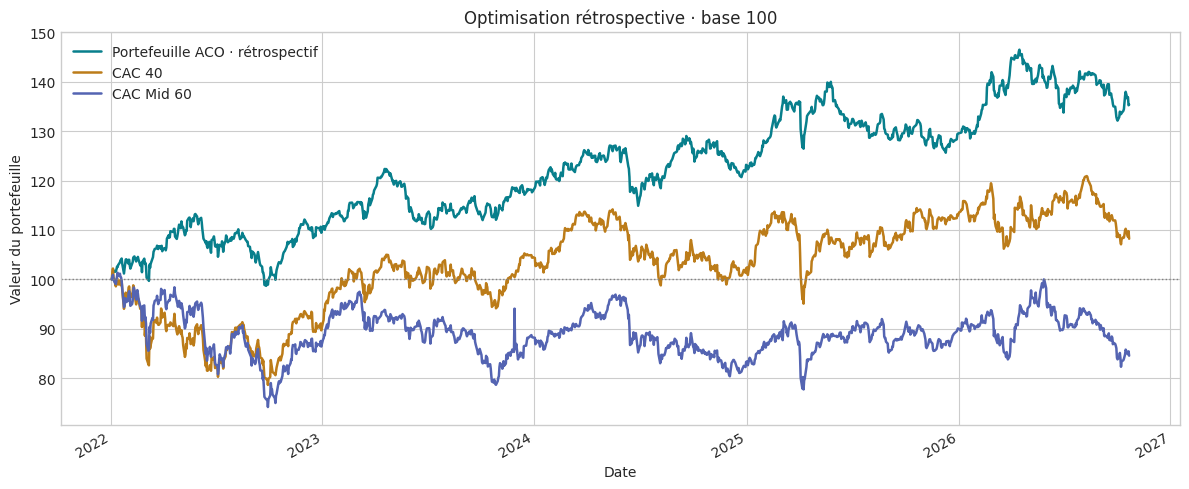

In [11]:
import matplotlib.pyplot as plt
curves = wealth_curves(prices, benchmarks, result['tickers'])
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 5))
curves.plot(ax=ax, color=['#087f8c','#bc7c19','#5464b2'], linewidth=1.8)
ax.axhline(100, color='grey', linestyle=':', linewidth=1)
ax.set(title='Optimisation rétrospective · base 100', xlabel='Date', ylabel='Valeur du portefeuille')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

## 11 · Lire la convergence

La volatilité du meilleur **admissible** ne peut qu'améliorer son classement au fil des cycles. Avant la première solution admissible, le déficit de CAGR prime. Le nombre de fourmis admissibles illustre le comportement de la colonie.

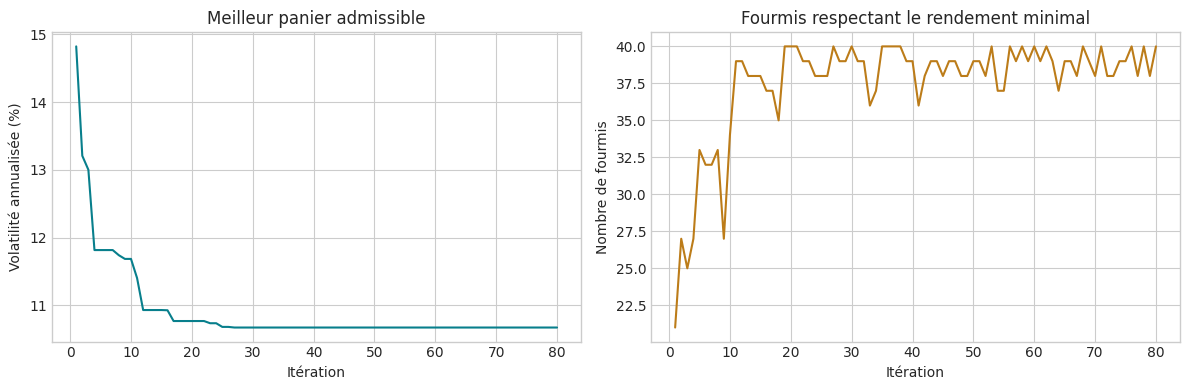

Ticker
ORA.PA     5.000000
BB.PA      5.000000
BN.PA      4.999998
ENX.PA     4.999997
FDJU.PA    4.999978
SAN.PA     4.999975
HO.PA      4.999961
BOL.PA     4.999936
CA.PA      4.999933
TTE.PA     4.990010
CAP.PA     0.050000
ACA.PA     0.050000
BVI.PA     0.050000
AC.PA      0.050000
BNP.PA     0.050000
AI.PA      0.050000
AIR.PA     0.050000
ERF.PA     0.050000
EL.PA      0.050000
ENGI.PA    0.050000
Name: Phéromone finale, dtype: float64

In [12]:
history = result['history']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['iteration'], 100*history['volatility'].where(history['feasible']), color='#087f8c')
axes[0].set(title='Meilleur panier admissible', xlabel='Itération', ylabel='Volatilité annualisée (%)')
axes[1].plot(history['iteration'], history['feasible_ants'], color='#bc7c19')
axes[1].set(title='Fourmis respectant le rendement minimal', xlabel='Itération', ylabel='Nombre de fourmis')
fig.tight_layout()
plt.show()
display(result['pheromones'].head(20).rename('Phéromone finale'))

## 12 · Exporter et prolonger l'étude

Mettre `EXPORTER = True` pour écrire les fichiers dans le dossier du notebook. Pour une étape suivante : comparer plusieurs graines à budget identique, introduire une validation chronologique hors échantillon, reconstruire les compositions historiques et intégrer les coûts de rééquilibrage. Un solveur de poids serait un autre problème d'optimisation.

In [13]:
EXPORTER = False
if EXPORTER:
    destination = Path('resultats_fourmis')
    destination.mkdir(exist_ok=True)
    selection.to_csv(destination / 'selection.csv')
    curves.to_csv(destination / 'trajectoires.csv', index_label='Date')
    audit.to_csv(destination / 'audit.csv', index=False)
    history.to_csv(destination / 'convergence.csv', index=False)
    pd.concat([prices,benchmarks],axis=1).to_csv(destination / 'clotures.csv',index_label='Date')
    (destination / 'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2), encoding='utf-8')
    (destination / 'parametres.json').write_text(json.dumps(asdict(config),indent=2), encoding='utf-8')
    print(destination.resolve())

## Références

- [Dorigo et Stützle · présentation de l'ACO](https://iridia.ulb.ac.be/comp2sys/research-aco.php.html)
- [Documentation yfinance.download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html)
- [CAC 40 · composition Euronext](https://live.euronext.com/en/product/indices/FR0003500008-XPAR)
- [CAC Mid 60 · composition et historique Euronext](https://live.euronext.com/en/product/indices/QS0010989117-XPAR)
- [Règles de la famille CAC · indices prix, NR et GR](https://live.euronext.com/sites/default/files/documentation/index-rules2/CAC_Index_Family_Rulebook.pdf)

L'adaptation à une sélection de titres (trace par action, heuristique inverse de la
volatilité et dépôt par rang) est le choix de ce projet, pas une recette financière
imposée par la méthode ACO.
